# 04 – Thí nghiệm: 4 cách xử lý mất cân bằng × 4 mô hình

**Đầu vào:** `data/processed/train.pkl`, `test.pkl`.
**Đầu ra:**
- `results/results.csv`: mỗi cấu hình một dòng (macro-F1, accuracy, precision/recall/F1 của 9 lớp, số dòng train, thời gian train và dự đoán);
- `results/predictions/<model>__<method>.csv`: nhãn dự đoán trên test, để notebook 05 phân tích mà không train lại.

| | Không xử lý | Class weight | Undersampling | SMOTE |
|---|---|---|---|---|
| Logistic Regression | ✓ | ✓ | ✓ | ✓ |
| KNN | ✓ | — | ✓ | ✓ |
| Random Forest | ✓ | ✓ | ✓ | ✓ |
| LightGBM | ✓ | ✓ | ✓ | ✓ |

15 cấu hình. KNN không có class weight vì KNN không tối ưu hàm lỗi khi huấn luyện, `KNeighborsClassifier` không có tham số này.

`RUN_MODELS` (ô đầu) chọn mô hình chạy lần này. Cấu hình đã có trong `results.csv` được bỏ qua, nên chạy lại notebook không train lại và không ghi trùng.

In [1]:
from pathlib import Path
import time
from datetime import datetime

import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("../data")
RESULTS_DIR = Path("../results")
PRED_DIR = RESULTS_DIR / "predictions"
RESULTS_FILE = RESULTS_DIR / "results.csv"
RANDOM_STATE = 42
CLASS_ORDER = ["BENIGN", "DoS", "PortScan", "DDoS", "Brute Force", "Web Attack", "Bot", "Infiltration", "Heartbleed"]

# Mô hình chạy trong lần này. Đợt sau thêm "LogisticRegression", rồi "KNN" (chậm nhất, chạy cuối).
RUN_MODELS = ["LightGBM", "RandomForest"]

## 1. Đọc dữ liệu

Dùng bản chia của notebook 02; mọi cấu hình được chấm trên cùng một tập test.

In [2]:
train = pd.read_pickle(DATA_DIR / "processed" / "train.pkl")
test = pd.read_pickle(DATA_DIR / "processed" / "test.pkl")

X_train, y_train = train.drop(columns="Label"), train["Label"]
X_test, y_test = test.drop(columns="Label"), test["Label"]

train_counts = y_train.value_counts().reindex(CLASS_ORDER)
print(f"Train: {len(X_train):,} rows, test: {len(X_test):,} rows, {X_train.shape[1]} features")
train_counts.rename("Train count").to_frame()

Train: 566,932 rows, test: 141,733 rows, 68 features


,Train count
Label,
BENIGN,297985
DoS,154868
PortScan,1480
DDoS,102409
Brute Force,7320
Web Attack,1714
Bot,1118
Infiltration,29
Heartbleed,9


## 2. Mức trần (undersampling) và mức sàn (SMOTE)

Không dùng `sampling_strategy="auto"` (cân bằng hoàn toàn): undersampling cắt mọi lớp xuống 9 mẫu (bằng Heartbleed), train còn 81 dòng; SMOTE nâng mọi lớp lên 297.985 (bằng BENIGN), train thành khoảng 2,7 triệu dòng, phần lớn là mẫu tổng hợp.

Thay vào đó:
- **Mức trần:** lớp đông hơn mức trần bị lấy mẫu ngẫu nhiên xuống bằng mức trần.
- **Mức sàn:** lớp ít hơn mức sàn được SMOTE bổ sung lên bằng mức sàn.

Hai mức chỉ được chọn từ thông tin của tập train (số mẫu từng lớp, thời gian chạy). Chọn theo điểm trên test thì test đã tham gia vào việc chọn cấu hình, kết quả báo cáo sẽ lạc quan.

Bảng dưới: số mẫu từng lớp với 3 mức ứng viên mỗi loại (chỉ đếm, chưa train).

In [3]:
def under_strategy(cap):
    # lớp nào nhiều hơn cap thì cắt xuống cap
    return {c: cap for c, n in train_counts.items() if n > cap}


def smote_strategy(floor):
    # lớp nào ít hơn floor thì tạo thêm mẫu cho đủ floor
    return {c: floor for c, n in train_counts.items() if n < floor}


candidates = {}
for cap in [20_000, 50_000, 100_000]:
    candidates[f"Cap {cap:,}"] = train_counts.clip(upper=cap)
for floor in [1_000, 5_000, 10_000]:
    candidates[f"Floor {floor:,}"] = train_counts.clip(lower=floor)

table = pd.DataFrame(candidates)
table.insert(0, "Original", train_counts)
table.loc["Total"] = table.sum()
table

,Original,"Cap 20,000","Cap 50,000","Cap 100,000","Floor 1,000","Floor 5,000","Floor 10,000"
Label,,,,,,,
BENIGN,297985,20000,50000,100000,297985,297985,297985
DoS,154868,20000,50000,100000,154868,154868,154868
PortScan,1480,1480,1480,1480,1480,5000,10000
DDoS,102409,20000,50000,100000,102409,102409,102409
Brute Force,7320,7320,7320,7320,7320,7320,10000
Web Attack,1714,1714,1714,1714,1714,5000,10000
Bot,1118,1118,1118,1118,1118,5000,10000
Infiltration,29,29,29,29,1000,5000,10000
Heartbleed,9,9,9,9,1000,5000,10000


**Thời gian chạy.** Ô dưới đo thời gian train Random Forest, LightGBM và ước tính thời gian dự đoán của KNN (mô hình chậm nhất) ở từng mức, chỉ dùng tập train. Mất khoảng 5 phút nên mặc định tắt (`MEASURE_TIME = False`). Kết quả đã đo trên MacBook 16 GB RAM:

| Mức | Số dòng train | RF train (giây) | LightGBM train (giây) | KNN dự đoán test, ước tính (giây) |
|---|---|---|---|---|
| Không xử lý | 566.932 | 20,0 | 17,3 | 55 |
| Trần 20.000 | 71.670 | 1,5 | 6,2 | 7 |
| Trần 50.000 | 161.670 | 4,4 | 8,2 | 14 |
| Trần 100.000 | 311.670 | 9,4 | 11,1 | 26 |
| Sàn 1.000 | 568.894 | 23,7 | 17,6 | 48 |
| Sàn 5.000 | 587.582 | 24,2 | 19,7 | 48 |
| Sàn 10.000 | 615.262 | 25,2 | 21,8 | 51 |

In [4]:
MEASURE_TIME = False

if MEASURE_TIME:
    query = X_train.sample(2_000, random_state=RANDOM_STATE)  # điểm hỏi cho KNN, lấy từ train
    rows = []
    options = [("No balancing", None)]
    options += [(f"Cap {c:,}", RandomUnderSampler(sampling_strategy=under_strategy(c), random_state=RANDOM_STATE)) for c in [20_000, 50_000, 100_000]]
    options += [(f"Floor {f:,}", SMOTE(sampling_strategy=smote_strategy(f), random_state=RANDOM_STATE)) for f in [1_000, 5_000, 10_000]]
    scaler = StandardScaler().fit(X_train)
    for name, sampler in options:
        Xs = scaler.transform(X_train)
        Xr, yr = (Xs, y_train) if sampler is None else sampler.fit_resample(Xs, y_train)
        record = {"Level": name, "Train rows": len(yr)}
        for label, model in [("RF train (s)", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)),
                             ("LightGBM train (s)", LGBMClassifier(random_state=RANDOM_STATE, verbose=-1))]:
            start = time.perf_counter()
            model.fit(Xr, yr)
            record[label] = round(time.perf_counter() - start, 1)
        knn = KNeighborsClassifier(n_neighbors=5).fit(Xr, yr)
        start = time.perf_counter()
        knn.predict(scaler.transform(query))
        record["KNN test prediction, estimated (s)"] = round((time.perf_counter() - start) * len(X_test) / len(query))
        rows.append(record)
    display(pd.DataFrame(rows))

**Chốt: trần 50.000, sàn 5.000.**

- Thời gian không phải ràng buộc (mọi mức: train dưới 30 giây, KNN dự đoán dưới 1 phút), nên chọn theo phân phối lớp của train.
- **Trần 50.000** cắt đúng ba lớp lớn (BENIGN, DoS, DDoS); BENIGN còn khoảng 1/6. Trần 100.000 gần như không chạm DDoS (chỉ bỏ 2.409 mẫu); trần 20.000 bỏ 93% BENIGN, mất nhiều thông tin về lưu lượng bình thường.
- **Sàn 5.000** nâng 5 lớp nhỏ (PortScan, Web Attack, Bot, Infiltration, Heartbleed) lên gần cỡ Brute Force (7.320), lớp nhỏ nhất mà baseline đã nhận gần hết (recall 0,997). Sàn 1.000 chỉ chạm Infiltration và Heartbleed; sàn 10.000 phải tạo thêm cả mẫu Brute Force.
- **Giới hạn:** Heartbleed tăng từ 9 lên 5.000 mẫu, Infiltration từ 29 lên 5.000. Mẫu SMOTE nằm trên đoạn thẳng nối các mẫu thật nên không thêm thông tin mới về hai lớp này.
- Hai mức không được tinh chỉnh. Muốn tinh chỉnh đúng cách cần tách tập validation từ train.

In [5]:
CAP = 50_000
FLOOR = 5_000

print("Undersampling caps:", under_strategy(CAP))
print("SMOTE raises:", smote_strategy(FLOOR))

Undersampling caps: {'BENIGN': 50000, 'DoS': 50000, 'DDoS': 50000}
SMOTE raises: {'PortScan': 5000, 'Web Attack': 5000, 'Bot': 5000, 'Infiltration': 5000, 'Heartbleed': 5000}


## 3. Pipeline cho từng cấu hình

`StandardScaler` → (resample) → mô hình. `Pipeline` của imbalanced-learn chỉ chạy bước resample khi `fit`; khi `predict`, test chỉ đi qua bộ chuẩn hóa.

| Cách xử lý | Thực hiện |
|---|---|
| Không xử lý | Không có bước resample |
| Class weight | `class_weight="balanced"`: trọng số lớp c là n / (9 · n_c), từ 0,21 (BENIGN) đến khoảng 7.000 (Heartbleed) |
| Undersampling | `RandomUnderSampler`, mức trần 50.000 |
| SMOTE | `SMOTE` (5 láng giềng), mức sàn 5.000; đặt sau `StandardScaler` vì SMOTE tìm láng giềng theo khoảng cách |

Tham số mô hình để mặc định, trừ các điểm dưới đây; `random_state=42` ở mọi chỗ có yếu tố ngẫu nhiên.

| Mô hình | Tham số |
|---|---|
| Logistic Regression | `max_iter=1000` |
| KNN | `n_neighbors=5`, `n_jobs=-1` |
| Random Forest | `n_estimators=100`, `n_jobs=-1` |
| LightGBM | `max_delta_step=1` (mục 3b), `verbose=-1` |

In [6]:
MODELS = ["LightGBM", "RandomForest", "LogisticRegression", "KNN"]
METHODS = ["none", "class_weight", "undersampling", "smote"]
METHOD_NAMES = {"none": "No balancing", "class_weight": "Class weight", "undersampling": "Undersampling", "smote": "SMOTE"}
MODEL_NAMES = {"LightGBM": "LightGBM", "RandomForest": "Random Forest", "LogisticRegression": "Logistic Regression", "KNN": "KNN"}


def make_model(model_name, balanced):
    weight = "balanced" if balanced else None
    if model_name == "LightGBM":
        return LGBMClassifier(class_weight=weight, max_delta_step=1, random_state=RANDOM_STATE, verbose=-1)
    if model_name == "RandomForest":
        return RandomForestClassifier(n_estimators=100, class_weight=weight, n_jobs=-1, random_state=RANDOM_STATE)
    if model_name == "LogisticRegression":
        return LogisticRegression(max_iter=1000, class_weight=weight, random_state=RANDOM_STATE)
    if model_name == "KNN":
        return KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
    raise ValueError(model_name)


def make_pipeline(model_name, method):
    steps = [("scaler", StandardScaler())]
    if method == "undersampling":
        steps.append(("sampler", RandomUnderSampler(sampling_strategy=under_strategy(CAP), random_state=RANDOM_STATE)))
    if method == "smote":
        steps.append(("sampler", SMOTE(sampling_strategy=smote_strategy(FLOOR), random_state=RANDOM_STATE)))
    steps.append(("clf", make_model(model_name, balanced=(method == "class_weight"))))
    return Pipeline(steps)


def train_size(method):
    # số dòng train mô hình thật sự nhìn thấy, sau bước cân bằng lại
    if method == "undersampling":
        return int(train_counts.clip(upper=CAP).sum())
    if method == "smote":
        return int(train_counts.clip(lower=FLOOR).sum())
    return len(y_train)


CONFIGS = [(m, k) for m in MODELS for k in METHODS if not (m == "KNN" and k == "class_weight")]
print(f"{len(CONFIGS)} configurations. Example pipeline for Random Forest + SMOTE:")
make_pipeline("RandomForest", "smote")

15 configurations. Example pipeline for Random Forest + SMOTE:


,steps,"[('scaler', ...), ('sampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,sampling_strategy,"{'Bot': 5000, 'Heartbleed': 5000, 'Infiltration': 5000, 'PortScan': 5000, ...}"
,random_state,42
,k_neighbors,5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1


### 3b. LightGBM: vì sao `max_delta_step=1`

Với tham số mặc định, LightGBM phân kỳ trên dữ liệu này: logloss trên chính tập train giảm vài vòng rồi tăng ngược. Boosting hoạt động đúng thì lỗi train giảm dần qua các vòng.

**Nguyên nhân.** Giá trị mỗi lá là một bước Newton: tổng gradient chia tổng hessian. Khi mô hình gán cho lớp đúng của một mẫu xác suất p gần 0 (thường gặp ở lớp hiếm), gradient gần −1 còn hessian, tỉ lệ với p(1 − p), gần 0. Giá trị lá vì thế rất lớn và đẩy dự đoán của cả lá đi quá xa.

**Cách sửa.** `max_delta_step=1` giới hạn giá trị lá trong [−1, 1]. Tham số này được chọn chỉ dựa trên lỗi train, không nhìn test.

Ô dưới so sánh hai thiết lập trên tập train, cấu hình Không xử lý (khoảng 1 phút). Đã kiểm tra ở cả 4 cách xử lý: với tham số mặc định đều có vòng lỗi train tăng (nặng nhất là undersampling, chỉ đoán đúng 41% tập train); với `max_delta_step=1` không vòng nào tăng.

Default            final loss 0.3801 | rounds where loss went up: 44 | train accuracy: 0.9880
max_delta_step=1   final loss 0.0012 | rounds where loss went up: 0 | train accuracy: 0.9996


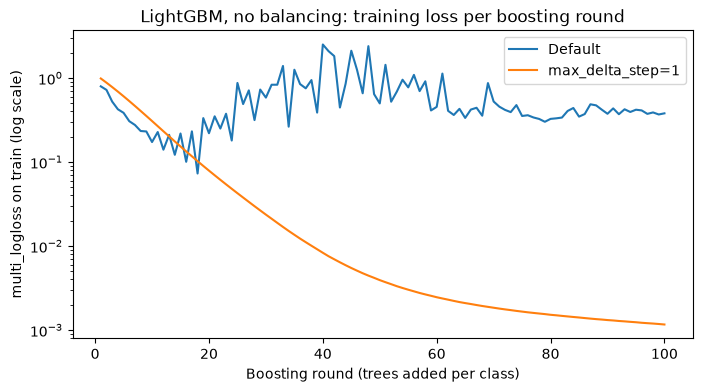

In [7]:
X_scaled = StandardScaler().fit_transform(X_train)
y_codes = y_train.astype("category").cat.codes  # nhãn đổi sang số 0–8 (eval_y không nhận nhãn dạng chữ)
curves = {}
for label, params in [("Default", {}), ("max_delta_step=1", {"max_delta_step": 1})]:
    lgbm = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, **params)
    lgbm.fit(X_scaled, y_codes, eval_X=X_scaled, eval_y=y_codes)
    curves[label] = lgbm.evals_result_["valid_0"]["multi_logloss"]
    train_acc = (lgbm.predict(X_scaled) == y_codes).mean()
    print(f"{label:<18} final loss {curves[label][-1]:.4f} | rounds where loss went up: "
          f"{sum(b > a for a, b in zip(curves[label], curves[label][1:]))} | train accuracy: {train_acc:.4f}")

curves = pd.DataFrame(curves)
curves.index = curves.index + 1
ax = curves.plot(figsize=(8, 4), logy=True, title="LightGBM, no balancing: training loss per boosting round")
ax.set_xlabel("Boosting round (trees added per class)")
ax.set_ylabel("multi_logloss on train (log scale)");

## 4. Chạy một cấu hình

`run_config` fit trên train, dự đoán trên test, tính macro-F1, accuracy và precision/recall/F1 từng lớp, rồi ghi ngay một dòng vào `results.csv` và lưu nhãn dự đoán vào `predictions/`. Ghi sau từng cấu hình nên notebook dừng giữa chừng cũng không mất kết quả đã chạy.

In [8]:
def run_config(model_name, method):
    model = make_pipeline(model_name, method)

    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    y_pred = model.predict(X_test)
    predict_time = time.perf_counter() - start

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, labels=CLASS_ORDER, zero_division=0
    )
    row = {
        "model": model_name,
        "method": method,
        "n_train": train_size(method),
        "macro_f1": f1_score(y_test, y_pred, labels=CLASS_ORDER, average="macro", zero_division=0),
        "accuracy": accuracy_score(y_test, y_pred),
        "train_time_s": round(train_time, 2),
        "predict_time_s": round(predict_time, 2),
        "run_at": datetime.now().isoformat(timespec="seconds"),
    }
    for i, label in enumerate(CLASS_ORDER):
        row[f"precision_{label}"] = precision[i]
        row[f"recall_{label}"] = recall[i]
        row[f"f1_{label}"] = f1[i]

    pd.DataFrame([row]).to_csv(RESULTS_FILE, mode="a", header=not RESULTS_FILE.exists(), index=False)
    pd.Series(y_pred, name="y_pred").to_csv(PRED_DIR / f"{model_name}__{method}.csv", index=False)
    return row

## 5. Vòng lặp

Chạy các cấu hình của những mô hình trong `RUN_MODELS`, theo thứ tự Không xử lý → Class weight → Undersampling → SMOTE, bỏ qua cấu hình đã có trong `results.csv`. Muốn chạy lại một cấu hình thì xóa dòng của nó trong `results.csv`.

LightGBM và Random Forest (8 cấu hình): khoảng 3 phút.

In [9]:
RESULTS_DIR.mkdir(exist_ok=True)
PRED_DIR.mkdir(exist_ok=True)
done = set()
if RESULTS_FILE.exists():
    done = set(pd.read_csv(RESULTS_FILE)[["model", "method"]].itertuples(index=False, name=None))

for model_name, method in CONFIGS:
    if model_name not in RUN_MODELS:
        continue
    if (model_name, method) in done:
        print(f"Skipped (already done): {MODEL_NAMES[model_name]} + {METHOD_NAMES[method]}")
        continue
    row = run_config(model_name, method)
    print(f"{MODEL_NAMES[model_name]:<20} {METHOD_NAMES[method]:<14} macro-F1 {row['macro_f1']:.4f}"
          f" | train {row['train_time_s']:6.1f} s | predict {row['predict_time_s']:5.1f} s | {row['n_train']:,} train rows")

LightGBM             No balancing   macro-F1 0.9801 | train   20.9 s | predict   1.1 s | 566,932 train rows
LightGBM             Class weight   macro-F1 0.9797 | train   21.2 s | predict   1.1 s | 566,932 train rows
LightGBM             Undersampling  macro-F1 0.9791 | train   11.3 s | predict   1.1 s | 161,670 train rows
LightGBM             SMOTE          macro-F1 0.9684 | train   23.8 s | predict   1.1 s | 587,582 train rows
Random Forest        No balancing   macro-F1 0.9633 | train   22.2 s | predict   0.2 s | 566,932 train rows
Random Forest        Class weight   macro-F1 0.9538 | train   13.2 s | predict   0.2 s | 566,932 train rows
Random Forest        Undersampling  macro-F1 0.9651 | train    6.6 s | predict   0.2 s | 161,670 train rows
Random Forest        SMOTE          macro-F1 0.9752 | train   31.1 s | predict   0.2 s | 587,582 train rows


## 6. Kết quả

Ba bảng tổng hợp từ `results.csv`; phân tích chi tiết ở notebook 05.

**Bảng 1 – Macro-F1.** So mỗi ô với cột Không xử lý của cùng hàng để thấy tác dụng của từng cách xử lý trên mô hình đó.

In [10]:
results = pd.read_csv(RESULTS_FILE)
results["Model"] = results["model"].map(MODEL_NAMES)
results["Method"] = results["method"].map(METHOD_NAMES)
method_cols = [METHOD_NAMES[k] for k in METHODS]

results.pivot(index="Model", columns="Method", values="macro_f1").reindex(columns=method_cols).round(4)

Method,No balancing,Class weight,Undersampling,SMOTE
Model,,,,
LightGBM,0.9801,0.9797,0.9791,0.9684
Random Forest,0.9633,0.9538,0.9651,0.9752


**Bảng 2 – Lớp hiếm.** Recall của Infiltration (7 mẫu test) và Heartbleed (2 mẫu) ghi dạng số đếm.

In [11]:
RARE = ["Web Attack", "Bot", "Infiltration", "Heartbleed"]
support = y_test.value_counts()

rare = results[["Model", "Method"]].copy()
for label in RARE:
    recall = results[f"recall_{label}"]
    if support[label] < 10:
        rare[f"Recall {label}"] = [f"{round(r * support[label])}/{support[label]}" for r in recall]
    else:
        rare[f"Recall {label}"] = recall.round(4)
    rare[f"Precision {label}"] = results[f"precision_{label}"].round(4)
rare

,Model,Method,Recall Web Attack,Precision Web Attack,Recall Bot,Precision Bot,Recall Infiltration,Precision Infiltration,Recall Heartbleed,Precision Heartbleed
0,LightGBM,No balancing,0.9907,0.9930,0.9462,0.8980,6/7,1.0,2/2,1.0
1,LightGBM,Class weight,0.9977,0.9885,0.9964,0.8554,6/7,1.0,2/2,1.0
2,LightGBM,Undersampling,0.9953,0.9884,0.9857,0.8594,6/7,1.0,2/2,1.0
3,LightGBM,SMOTE,0.9930,0.9907,0.9642,0.8622,5/7,1.0,2/2,1.0
4,Random Forest,No balancing,0.9534,0.9976,0.8315,0.9317,5/7,1.0,2/2,1.0
5,Random Forest,Class weight,0.9837,0.9837,0.9785,0.5460,6/7,1.0,2/2,1.0
6,Random Forest,Undersampling,0.9720,0.9905,0.9211,0.8712,5/7,1.0,2/2,1.0
7,Random Forest,SMOTE,0.9580,0.9976,0.8817,0.9111,6/7,1.0,2/2,1.0


**Bảng 3 – Kích thước train và thời gian chạy.**

In [12]:
results[["Model", "Method", "n_train", "train_time_s", "predict_time_s"]].rename(columns={
    "n_train": "Train rows", "train_time_s": "Train (s)", "predict_time_s": "Predict (s)",
})

,Model,Method,Train rows,Train (s),Predict (s)
0,LightGBM,No balancing,566932,20.89,1.15
1,LightGBM,Class weight,566932,21.24,1.11
2,LightGBM,Undersampling,161670,11.31,1.12
3,LightGBM,SMOTE,587582,23.79,1.11
4,Random Forest,No balancing,566932,22.16,0.23
5,Random Forest,Class weight,566932,13.25,0.21
6,Random Forest,Undersampling,161670,6.62,0.24
7,Random Forest,SMOTE,587582,31.14,0.23


**Kiểm tra tái lập.** Random Forest + Không xử lý trùng cấu hình baseline ở notebook 03, nên macro-F1 phải bằng 0,9633.

In [13]:
rf_none = results.query("model == 'RandomForest' and method == 'none'")
if len(rf_none):
    assert round(rf_none["macro_f1"].iloc[0], 4) == 0.9633, rf_none["macro_f1"].iloc[0]
    print("Matches notebook 03 baseline: macro-F1 0.9633")

Matches notebook 03 baseline: macro-F1 0.9633
